# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [46]:
# importar librerías
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [47]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')#completa el código
usage = pd.read_csv('/datasets/usage.csv')#completa el código

In [48]:
# mostrar las primeras 5 filas de plans
plans.head(5)

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [49]:
# mostrar las primeras 5 filas de users
users.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [50]:
# mostrar las primeras 5 filas de 
usage.head(5)

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [51]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [52]:
# inspección de plans con .info()
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [53]:
# inspección de users con .info()
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [54]:
# inspección de usage con .info()
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [55]:
# cantidad de nulos para users
# Cantidad de valores nulos)
print(users.isna().sum().sort_values(ascending = False))
print('-'*20)
# Proporción de valores nulos)
print(users.isna().mean().sort_values(ascending = False)*100)

churn_date    3534
city           469
user_id          0
first_name       0
last_name        0
age              0
reg_date         0
plan             0
dtype: int64
--------------------
churn_date    88.350
city          11.725
user_id        0.000
first_name     0.000
last_name      0.000
age            0.000
reg_date       0.000
plan           0.000
dtype: float64


In [56]:
# cantidad de nulos para usage
print(usage.isna().sum().sort_values(ascending = False))
print('-'*20)
print(users.isna().mean().sort_values(ascending = False)*100)

duration    22076
length      17896
date           50
id              0
user_id         0
type            0
dtype: int64
--------------------
churn_date    88.350
city          11.725
user_id        0.000
first_name     0.000
last_name      0.000
age            0.000
reg_date       0.000
plan           0.000
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?
  
+ En el dataset de Users se evidencia valores faltantes para la fecha de abandono con aproximadamente 88% y ciudad del usuario con aproximadamente 12%.
+ En el dataset de Usage se evidencia valores faltantes para la duración con aproximadamente 55%, longitud con aproximadamente 45% y fecha con el 0,1%
  
- Indica qué harías: ¿imputar, eliminar, ignorar?
  
+ **En Users los valores faltantes del atributo:**
+ Fecha de abandono deben ser ignorados, ya que aparecen faltantes debido a que es posible que la mayoria de los usuarios conserven su plan telefonico.
+ Ciudad se dejarían nulos ya que eliminar filas significa perdida importante de información y la imputación no es posible.

+ **En Usage los valores faltantes del atributo:**
+ Duracion deben permanecer como nulos o imputados con valor cero ya que es posible que estos faltantes pertenezcan a mensajes, los cuales no tienen duración.
+ Longitud deben permaneces como nolos o ser imputados con valor cero ya que es posible que estos faltantes pertenecan a llamadas, los cuales no tienen longitud.
+ Fecha deben ser dejados como nulos ya que para el analisis que requieren los dataset es informacion no relevante.

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [57]:
# explorar columnas numéricas de users
users.describe()

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


- La columna `user_id` aunque es de tipo de numerico no aporta valor para las metricas estadisticas
- La columna `age` hay uno o varios sentinels (valores inválidos) importantes ya que el minimo se registra en -999, lo cual afecta directamente las estadísticas

In [58]:
# explorar columnas numéricas de usage
usage.describe()

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


- Las columnas `id` y `user_id` aunque son de tipo de numérico no aportan valor para las metricas estadisticas
- Las columnas 'duration' y 'length' tienen desviaciones estandar altas, y el valor máximo para longitud de mensajes debe ser sujeto a revisión. No obstante sus estadísticas a simple vista no presentan anomalias.  

In [59]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']
users[columnas_user].describe()


,city,plan
count,3531,4000
unique,7,2
top,Bogotá,Basico
freq,808,2595


- La columna `city` muestra nuevamente que hay valores nulos o faltantes, el registro presenta información de 7 ciudades contando a Bogotá como la que mayor cantidad de usuarios con 808 registrados.
- La columna `plan` nos confirma que no tiene datos faltantes y que solo son 2 opciones de plan siendo el Básico el más recurrente.

In [60]:
# explorar columna categórica de usage
# completa el código
usage['type'].describe() 

count     40000
unique        2
top        text
freq      22092
Name: type, dtype: object

- La columna `type` demuestra que el modo de comunicación mas usado es através de mensaje de texto (text) con una frecuencia de aproximadamente 55%, esto confirma nuestra hipótesis que el 55% de nulos en el atributo de llamada se debe a que esos datos no tienen duración.


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?
- Encontré sentinels en la columna de edad (age) del dataset Users, registrando valores de -999 años, para los demas dataset no se encuentran anomalías. 
- ¿Qué acción tomarías?
- Determinar cuales son los outliers extremos y winsorizarlos o imputar a estos valores con la media o mediana son ambas opciones practicas para normalizar las estadísticas

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [61]:
# Convertir a fecha la columna `reg_date` de users
# completa el código
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')  
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   user_id     4000 non-null   int64         
 1   first_name  4000 non-null   object        
 2   last_name   4000 non-null   object        
 3   age         4000 non-null   int64         
 4   city        3531 non-null   object        
 5   reg_date    4000 non-null   datetime64[ns]
 6   plan        4000 non-null   object        
 7   churn_date  466 non-null    object        
dtypes: datetime64[ns](1), int64(2), object(5)
memory usage: 250.1+ KB


In [62]:
# Convertir a fecha la columna `date` de usage
# completa el código
usage['date'] = pd.to_datetime(usage['date'], errors='coerce')
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   id        40000 non-null  int64         
 1   user_id   40000 non-null  int64         
 2   type      40000 non-null  object        
 3   date      39950 non-null  datetime64[ns]
 4   duration  17924 non-null  float64       
 5   length    22104 non-null  float64       
dtypes: datetime64[ns](1), float64(2), int64(2), object(1)
memory usage: 1.8+ MB


In [63]:
# Revisar los años presentes en `reg_date` de users
print(users['reg_date'].dt.year.value_counts(dropna=False))

2024    1330
2023    1316
2022    1314
2026      40
Name: reg_date, dtype: int64


En `reg_date`se evidencian 40 registros haciendo referencia al año 2026, siendo esto inconsistente con la instruccion inicial en donde se solicita trabajar solo con información registrada hasta el año 2024

In [64]:
# Revisar los años presentes en `date` de usage
print(usage['date'].dt.year.value_counts(dropna=False))

2024.0    39950
NaN          50
Name: date, dtype: int64


En `date`, se registran 50 valores faltantes (0,1% del total de registros como se habia informado anteriormente) y los demás corresponden a registros solo del año 2024, por lo tanto solo tiene historial de consumo de este año. 
Basaremos el análisis en estas fechas.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
- Sí. Hay registros con el año 2026 de vinculación (reg_date) en el dataset Users. 
- ¿Qué harías con ellas?
- Al ser un porcentaje pequeño respecto al total de registros (1%), lo más adecuado es eliminar dichos registros ya que no se tiene certeza del año correcto al cual pertenecen.

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [65]:
print('La cantidad total de datos con sentinel -999 es:',(users['age']==-999).sum())

La cantidad total de datos con sentinel -999 es: 55


In [66]:
# Reemplazar -999 por la mediana de age

age_mediana = users['age'].median()
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.122250
std        17.690408
min        18.000000
25%        33.000000
50%        47.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [67]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?', pd.NA)

# Verificar cambios
users['city'].value_counts(dropna=False)

Bogotá      808
CDMX        730
Medellín    616
NaN         565
GDL         450
Cali        424
MTY         407
Name: city, dtype: int64

In [68]:
# Marcar fechas futuras como NA para reg_date
users.loc[users['reg_date'].dt.year == 2026, 'reg_date'] = pd.NaT
# Verificar cambios
users['reg_date'].dt.year.value_counts(dropna=False)

2024.0    1330
2023.0    1316
2022.0    1314
NaN         40
Name: reg_date, dtype: int64

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [69]:
# Verificación MAR en usage (Missing At Random) para duration
def contar_sinduracion (nulos):
    total_nulos_duracion = nulos.isna().sum()
    return total_nulos_duracion

usage.groupby('type')['duration'].apply(contar_sinduracion)

type
call        0
text    22076
Name: duration, dtype: int64

In [70]:
# Verificación MAR en usage (Missing At Random) para length
def contar_sinlongitud (nulos):
    total_nulos_longitud = nulos.isna().sum()
    return total_nulos_longitud
usage.groupby('type')['length'].apply(contar_sinlongitud)

type
call    17896
text        0
Name: length, dtype: int64

Haz doble clic aquíy escribe que tu diagnostico de nulos en `duration` y `length`
- Tal como se habia predicho, los nulos para la columna duracion ('duration') se deben a registros de mensaje de texto ('length') y los nulos en la longitud ('length') corresponden a registros de duracion, confirmando que son datos faltantes de tipo MAR, teniendo en cuenta que dichos faltantes dependen de otras variables. No se observan mas causales de nulos.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [71]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas


# Agrupar información por usuario
usage_agg = usage.groupby('user_id')[['is_text', 'is_call', 'duration']].sum().reset_index()

# observar resultado
usage_agg.head(3)

,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [72]:
# Renombrar columnas
usage_agg= usage_agg.rename(columns={'is_text': 'cant_mensajes', 'is_call': 'cant_llamadas', 'duration':'cant_minutos_llamadas'})
# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamadas
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [73]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = pd.merge(users, usage_agg, on='user_id', how='left')
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamadas
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [74]:
# Resumen estadístico de las columnas numéricas
columnas_numericas = user_profile.select_dtypes(include='number').columns.tolist() 

#removemos de las metricas user_id, aunque su tipo de dato es numerico no aporta metricas
if 'user_id' in columnas_numericas:
    columnas_numericas.remove('user_id')
    
user_profile[columnas_numericas].describe()

,age,cant_mensajes,cant_llamadas,cant_minutos_llamadas
count,4000.000000,3999.000000,3999.000000,3999.000000
mean,48.122250,5.524381,4.478120,23.317054
std,17.690408,2.358416,2.144238,18.168095
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.120000
50%,47.000000,5.000000,4.000000,19.780000
75%,63.000000,7.000000,6.000000,31.415000
max,79.000000,17.000000,15.000000,155.690000


In [75]:
# Distribución porcentual del tipo de plan
user_profile['plan'].value_counts(normalize=True)*100

Basico     64.875
Premium    35.125
Name: plan, dtype: float64

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

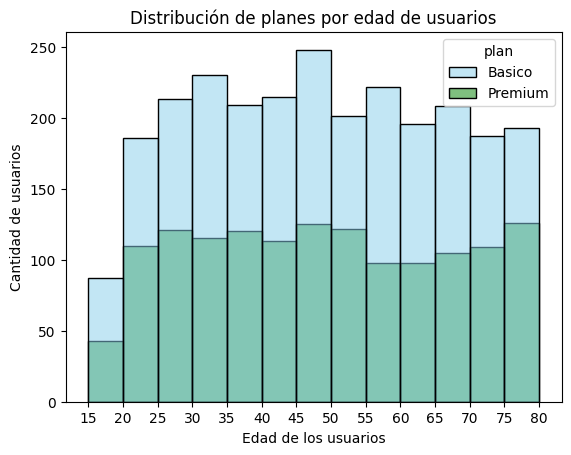

In [76]:
# Histograma para visualizar la edad (age)
sns.histplot(
    data=user_profile,
    x= 'age',
    hue = 'plan',
    binrange = (15,80),
    binwidth= 5,
    palette=['skyblue','green']
)
plt.xticks(range(15,81, 5))
plt.title('Distribución de planes por edad de usuarios')
plt.xlabel('Edad de los usuarios')
plt.ylabel('Cantidad de usuarios')
plt.show()

💡Insights: 
- Distribución casi uniforme de la cantidad de usuarios entre los rangos de edades, a excepción de las edades entre 18 y 20 años donde el poder adquisitivo de los usuarios es menor o donde muy posiblemente el plan adquirido por estos clientes se encuentra bajo la titularidad de un tercero (padres o parientes máss adultos). Se resalta que el rango de edad entre los 45 y 50 años es el que mayor cantidad de usuarios presenta.
- Tambien se puede observar que el plan Básico predomina en todos los rangos de edades siendo el mas atractivo para la base de clientes de la compañía, además se observa que en casi todas las edades llega a ser aproximadamente el doble en cantidad respecto al plan Premium, y solo en rangos de edades de 75 a 79 años esta brecha se reduce.

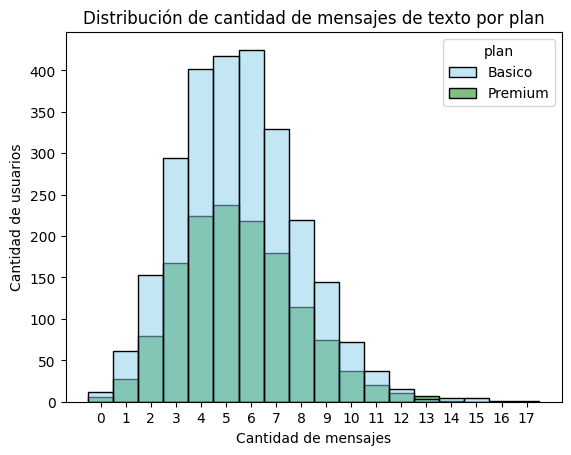

In [77]:
# Histograma para visualizar la cant_mensajes

sns.histplot(
    data=user_profile,
    x= 'cant_mensajes',
    hue = 'plan',
    discrete = True,
    binrange = (0,17),
    binwidth= 1,
    palette=['skyblue', 'green']
)
plt.xticks(range(0,18, 1))
plt.title('Distribución de cantidad de mensajes de texto por plan')
plt.xlabel('Cantidad de mensajes')
plt.ylabel('Cantidad de usuarios')
plt.show()



💡Insights: 
- Hay una distribucion de sesgo a la derecha, en donde el envio de mensajes de texto se manifiesta en pequeñas cantidades; muy pocos usuarios envian mas de 10 mensajes de texto al mes.
- Las proporciones diferenciales de un plan respecto al otro son parecidas es decir, que para el plan Básico en todos los conteos de mensajes, el numero de usuarios es aproximadamente el doble que para el plan Premium, muy a pesar de que el plan premiun ofrece una mayor cantidad de mensajes incluidos respecto al plan Básico.
- Teniendo en cuenta lo anterior, una mayor cantidad de mensajes de texto como opcion de mejora no es un buen enganche para atraer nuevos clientes o para incentivar la migración de clientes poseedores de plan básico  al plan Premium.


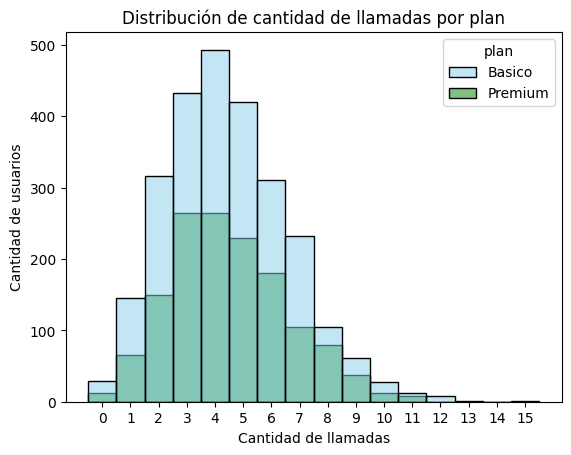

In [78]:
# Histograma para visualizar la cant_llamadas

sns.histplot(
    data=user_profile,
    x= 'cant_llamadas',
    hue = 'plan',
    discrete = True,
    binrange = (0,15),
    binwidth= 1,
    palette=['skyblue', 'green']
)
plt.xticks(range(0, 16, 1))
plt.title('Distribución de cantidad de llamadas por plan')
plt.xlabel('Cantidad de llamadas')
plt.ylabel('Cantidad de usuarios')
plt.show()



💡Insights: 
- Hay una distribucion de sesgo a la derecha, en donde las llamadas se manifiesta en pequeñas cantidades; muy pocos usuarios realizan llamadas mas de 10 veces al mes.
- Las proporciones diferenciales de un plan respecto al otro son parecidas; es decir, que para el plan Básico en todos los conteos de llamadas, el numero de usuarios es aproximadamente el doble que para el plan Premium, muy a pesar de que el plan premiun ofrece una mayor cantidad de minutos incluidos respecto al plan Básico. Lo que sugiere que la oferta comercial no necesariamente empuja a una mayor frecuencia de llamadas.
- Teniendo en cuenta lo anterior, una mayor cantidad de minutos como opción de mejora no es un buen enganche para atraer nuevos clientes o para incentivar la migración de clientes poseedores de plan básico al plan Premium. Sin embargo, para contemplar por completo esta conclusión se debe verificar si el factor diferenciador radica en la duración de cada llamada, es decir en el total de minutos consumidos al mes.

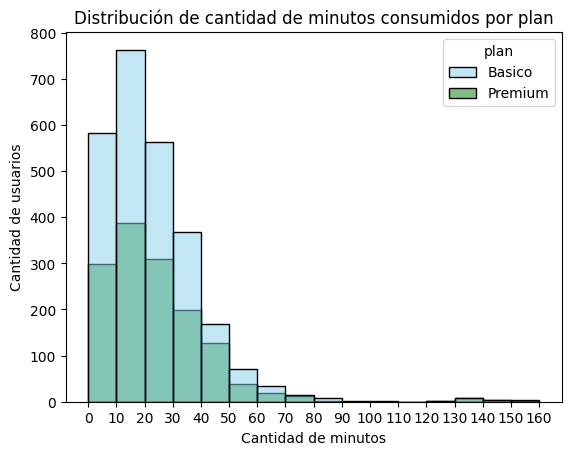

In [79]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(
    data=user_profile,
    x= 'cant_minutos_llamadas',
    hue = 'plan',
    binrange = (0,160),
    binwidth= 10,
    palette=['skyblue', 'green']
)
plt.xticks(range(0, 161, 10))
plt.title('Distribución de cantidad de minutos consumidos por plan')
plt.xlabel('Cantidad de minutos')
plt.ylabel('Cantidad de usuarios')
plt.show()



💡Insights: 
- Se observa una distribución con un marcado sesgo a la derecha, donde la gran mayoría de los usuarios consumen entre 0 y 40 minutos al mes; es sumamente raro encontrar clientes que superen los 60 minutos de consumo total.
- La diferencia proporcional se mantiene constante en todo el histórico de consumo: el número de usuarios en el plan Básico duplica al plan Premium en cada barra, confirmando que contar con más minutos incluidos no empuja a los usuarios Premium a hablar por más tiempo.
- Al igual que con los mensajes y la cantidad de llamadas, aumentar la bolsa de minutos tradicionales no representa un valor agregado ni un enganche efectivo para el portafolio. -
- Para mitigar la deserción o incentivar la migración al plan Premium, la compañía debe explorar otros beneficios (como mayor cantidad en las gigas de datos, llamadas internacionales o roaming) en lugar de insistir en la telefonía convencional.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

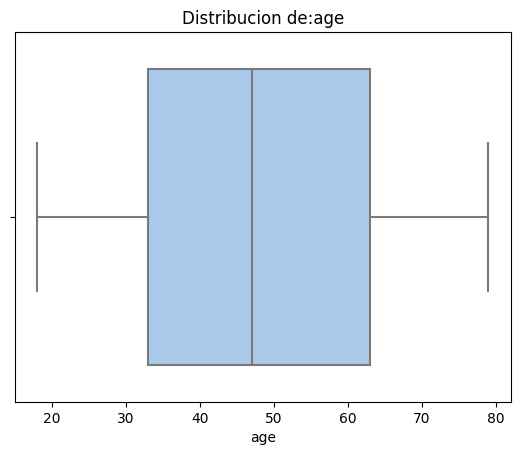

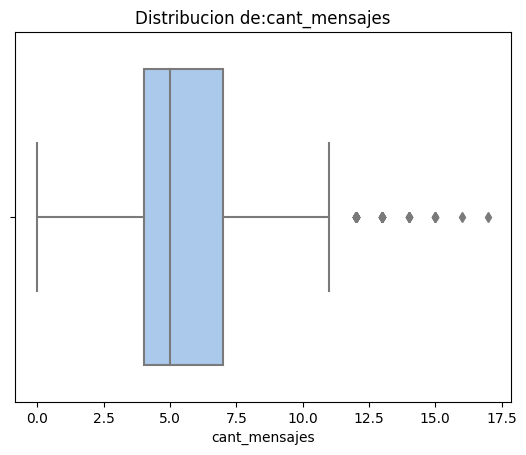

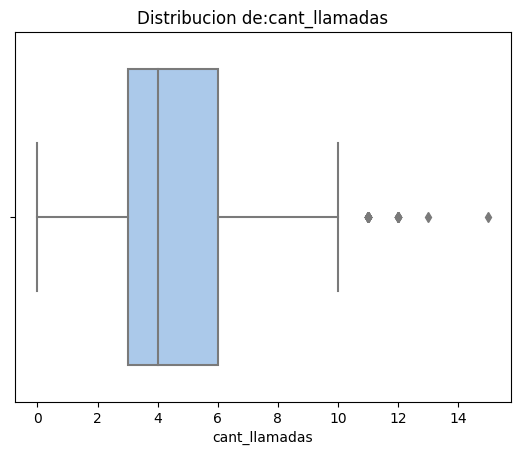

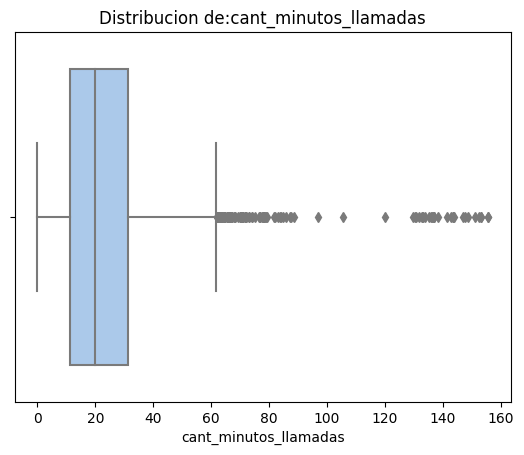

In [80]:
# Visualizando usando BoxPlot 
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamadas']

for col in columnas_numericas:
    sns.boxplot(data=user_profile, x= col, palette = 'pastel')
    plt.title(f'Distribucion de:{col}')
    plt.show()

💡Insights: 
- Age: No presenta outliers
- cant_mensajes: Presenta outliers
- cant_llamadas: Presenta outliers
- cant_minutos_llamada: Presenta una gran cantidad de outliers

In [81]:
# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamadas']
nombres_completos = {'cant_mensajes': 'Cantidad de Mesajes', 'cant_llamadas': 'Cantidad de Llamadas', 'cant_minutos_llamadas': 'Cantidad Total de Minutos'}
for i in columnas_limites:
    Q3 = user_profile[i].quantile(0.75)
    Q1 = user_profile[i].quantile(0.25)
    IQR = Q3 - Q1
    upper = Q3 + 1.5*IQR
    nombres_impresion = nombres_completos[i]
    print(f'El limite superior de {nombres_impresion} es :', upper)


El limite superior de Cantidad de Mesajes es : 11.5
El limite superior de Cantidad de Llamadas es : 10.5
El limite superior de Cantidad Total de Minutos es : 61.8575


In [82]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamadas
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,23.317054
std,2.358416,2.144238,18.168095
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.120000
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.415000
max,17.000000,15.000000,155.690000


💡Insights: 
- cant_mensajes: Se mantienen los outliers porque estos son datos con una alta probabilidad de ser reales; no son datos que distorsionen la realidad del comportamiento de los usuarios.
- cant_llamadas: Se mantienen los outliers porque estos son datos con una alta probabilidad de ser reales; no son datos que distorsionen la realidad del comportamiento de los usuarios.
- cant_minutos_llamadas: Se mantienen los outliers porque estos son datos con una alta probabilidad de ser reales; no son datos que distorsionen la realidad del comportamiento de los usuarios.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [83]:
# Crear columna grupo_uso


def segmentos_uso (fila):
    if fila['cant_llamadas'] < 5 and fila['cant_mensajes'] < 5:
        return 'Bajo uso'
    elif fila['cant_llamadas'] < 10 and fila['cant_mensajes'] < 10:
        return 'Uso medio'
    else:
        return 'Alto uso'

user_profile['grupo_uso']= user_profile.apply(segmentos_uso, axis=1)

    

In [84]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamadas,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [85]:
# Crear columna grupo_edad
def segmentos_edad (fila):
    if fila['age'] < 30:
        return 'Joven'
    elif fila['age'] < 60:
        return 'Adulto'
    else:
        return 'Adulto Mayor'

user_profile['grupo_edad']= user_profile.apply(segmentos_edad, axis=1)


In [86]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamadas,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

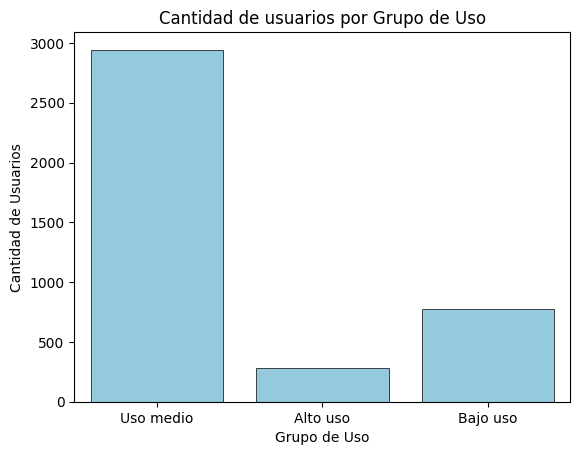

In [87]:
# Visualización de los segmentos por uso
sns.countplot(
    data = user_profile,
    x = 'grupo_uso',
    color = 'skyblue',
    edgecolor = 'black',
    linewidth = 0.5
)
plt.title ('Cantidad de usuarios por Grupo de Uso')
plt.xlabel ('Grupo de Uso')
plt.ylabel('Cantidad de Usuarios')
plt.show()

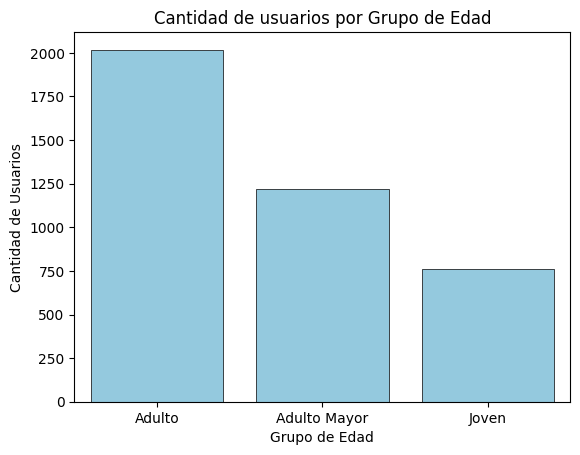

In [88]:
# Visualización de los segmentos por edad
sns.countplot(
    data = user_profile,
    x = 'grupo_edad',
    color = 'skyblue',
    edgecolor = 'black',
    linewidth = 0.5
)
plt.title ('Cantidad de usuarios por Grupo de Edad')
plt.xlabel ('Grupo de Edad')
plt.ylabel('Cantidad de Usuarios')
plt.show()


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- **¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?**

  Se logra evidenciar que los dataset suministrados estan bastante completos, el correspondiente a **plans** no presenta anomalías y en cuanto a **usage** presenta registros que son MAR debido a la naturaleza de la informacion presentada, esto se debe a que los valores faltantes en el atributo de duracion de llamadas (duration) es la cantidad de valores que corresponden a longitud de mensajes (length) y viceversa.

  Para el dataset **users** se evidencian un 12% de valores faltantes en el atributo de ciudad de los usuarios, estos fueron reemplazados como valores no identificados ya que los analisis realizados no contemplan la localización geográfica de los usuarios; otro de los atributos es sujetos a revision es la fecha de abandono (churn_date), en donde los datos se evidenciaban como faltantes con justa razon debido a que al no existir una fecha de cancelacion del plan dichos datos son inexistentes. Asimismo, se detectó una inconsistencia en la fecha de registro de los usuarios (reg_date) con 40 registros (cerca del 1%) que apuntaban erróneamente al año 2026, los cuales excedían el marco temporal del estudio topado en 2024, con el fin de no afectar las estadísticas del estudio y teniendo en cuenta que es un porcentaje reducido respecto al total de registros. Con este ajuste, la distribución de la edad quedó completamente normalizada.

  En cuanto a los sentinels en **users** fueron identificados para el atributo de edad('age') en una proporción del 1,4%, los cuales fueron imputados con la mediana con el fin de no afectar las estadisticas del estudio y teniendo en cuenta que es un porcentaje reducido respecto al total de registros. Una vez fueron imputados estos registros, no se identificaron otros outliers para el atributo age. 

  Para el dataset resultado de la union de lo **users** y **usage** se identificaron valores extremos en los atributos de cantidad de llamadas (cant_llamadas), cantidad de mensajes (cant_mensajes), y total de minutos en llamadas (cant_minutos_llamadas) mediante el metodo de IQR, no obstante, se concluye que estos valores extremos no distorsionan la realidad al ser datos razonables y en cambio winsorizarlos o eliminarlos si afectarian fuertemente las metricas estadisticas del estudio.


- **¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?**

  La informacion ha sido segmentada en dos dimensiones: la primera por el grado de consumo de los usuarios, y el segundo por la edad de los usuarios.

  Para el primer segmento (grado de consumo) se identifica que los usuarios tienen un grado de **Uso medio**, realizando entre 5 y 10 llamadas y entre 5 y 10 mensajes, respecto a una cantidad maxima de 15 para llamadas y 17 mensajes, el cual es significativamente más alto que los demás niveles, llegando a ser aproximadamente el triple del segmento de **Bajo uso** y el doble del segmento de **Alto uso**. El siguiente segmento con mas registros es de 'uso bajo' con menos de 5 llamadas y menos de 5 mensajes. Finalmente el segmento con menor participacion es el de grado de 'uso alto' con mas de 10 llamadas y mas de 10 mensajes.

  Para el segundo segmento (edad de los usuarios) se identifica diferencia bastante marcada entre los rangos de edad. El rango predominante es **Adulto** de edades entre los 30 y 60 años con aproximadamente 2.000 usuarios registrados representando la principal base de cliente. El segundo lugar lo ocupa el rango **Adulto mayor** que son los usuarios mayores de 60 años, con aproximadamente 1250 usuarios registrados. Por ultimo, usuarios menores de 30 años clasificados en el rango **Joven** con aproximadamente 750 usuarios registrados, siendo estos el grupo con menor incidencia en el mercado.
  
- **¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?**

    Los segmentos más valiosos para ConnectaTel estan sin duda en el ofrecimiento de su plan Básico, donde aproximadamente el 65% de sus usuarios tiene suscripción a dicho plan el cual predomina en todos los rangos de edades. Ademas el grueso de los usuarios se concentra en clientes de mediana y avanzada edad, con grado de uso moderado en lo que respecta a la ejecución de llamadas y envío de mensajes de texto. Este perfil demográfico representa el núcleo de estabilidad financiera para la compañía, ya que los usuarios adultos y de la tercera edad tienden a mostrar un comportamiento de consumo predecible y una mayor lealtad al servicio (menor probabilidad de abandono) en comparación con los segmentos más jóvenes.

- **¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?**

    Debido al sesgo hacia la derecha de los atributos de cantidad de llamadas, cantidad de mensajes, y total de minutos, se encuentra un patron de outliers de "grandes" cantidades respecto a la media y mediana, no obstante, lo principal a resaltar de dicho patron, es que los datos extremos no distorcionan la realidad del negocio y son datos con alta probabilidad que representen sucesos de la vida real, por lo tanto, son outliers necesarios para las metricas del negocio. 

    Para el negocio, estos outliers implican la identificación de un nicho de usuarios con alta actividad, los cuales representan la oportunidad comercial para estrategias de *up-selling* (migración a planes con mayor margen de ganancia). Asimismo, mantener estos registros es vital para que el equipo de infraestructura pueda dimensionar correctamente las capacidades máximas de la red y evitar saturaciones en el servicio.

- **¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?**

    En primer lugar, medir el uso de internet movil, el dataset solo se basa en registros de uso de uso de telefonia básica, sin embargo, teniendo en cuenta las nuevas tendencias de comunicación en donde la internet tiene la mas alta incidencia, se debe verificar el uso de datos moviles, los picos de uso, los rangos de edad en donde mas se usa, y los segmentos de la población que mas requiere de datos y que sobrepasa los limites de cobertura de gigas incluidas en cada plan.

    Hay que tener en cuenta que principalmente la poblacion joven y de mediana edad, hoy por hoy prefiere el uso de datos y el envio de mensajes por aplicaciones moviles como medio de comunicacion muy por encima del las llamadas de voz o mensajes de texto. Por tal motivo, considero necesario ampliar el abanico de opciones de planes con diferentes rangos de precio en donde se ofrezcan distintas cantidades de gigas de datos y de esa manera hacer mas visible el atractivo de los planes Premium favoreciendo la migracion de clientes a este tipo de planes.

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**

- Inconsistencias y datos nulos: Se identificó un 12% de registros faltantes en el atributo de ciudad, anomalías de fechas futuras (año 2026) en la fecha de registro y un 1.4% de valores "sentinel" (-999) en la edad de los usuarios que requirieron imputación con la mediana.
  
- Datos faltantes por diseño (MAR): Los valores nulos en el dataset de consumo no eran errores, sino datos ausentes de forma aleatoria (MAR); la falta de duración en llamadas correspondía a mensajes de texto, y viceversa. Los valores extremos (outliers) en consumos se mantuvieron por reflejar comportamientos reales.


🔍 **Segmentos por Edad**

- Predominio del mercado adulto: El grueso de los usuarios se concentra de forma muy marcada en la población de **Adultos (30 a 60 años)** con aproximadamente 2,000 registros, seguidos por los **Adultos Mayores** con 1,250 usuarios.
  
- Baja participación juvenil: El segmento **Joven** (menores de 30 años) representa la menor incidencia en el mercado con apenas 750 registros, evidenciando una desconexión actual de la oferta con el público de menor edad.


📊 **Segmentos por Nivel de Uso**

- Concentración en el uso moderado: La mayor cantidad de usuarios se clasificó en el nivel de **'Uso medio'** (usuarios que consumen entre 5 y 10 llamadas/mensajes), siendo el triple del segmento de 'Bajo uso' y el doble de 'Alto uso'.
  
- Comportamiento de consumo sesgado: Las métricas de llamadas, mensajes y minutos acumulados mensuales muestran un marcado sesgo a la derecha. La gran mayoría de clientes consume menos de 40 minutos o 10 mensajes, manteniendo un comportamiento idéntico entre planes.


➡️ Esto sugiere que la estrategia de enganche comercial del Plan Premium está fallando. Ofrecer más minutos y SMS convencionales no aporta un valor agregado percibido por los clientes, ya que la base de usuarios actual simplemente no utiliza los canales de telefonía tradicional a su máxima capacidad. El Plan Básico es el producto dominante con el 65% de adopción porque cubre perfectamente las necesidades de uso moderado de los segmentos de mayor edad (Adultos y Adultos Mayores), quienes sostienen la estabilidad financiera de la empresa por su lealtad y consumo predecible.


💡 **Recomendaciones**

- Reestructurar el Portafolio Comercial, transformando los beneficios del Plan Premium, esto se traduce en eliminar las bolsas de minutos u obsoletos SMS, e introducir en su lugar bolsas competitivas de navegación por internet, roaming o empaquetamiento de streaming de entretenimiento.
  
- Modernizar la captura de datos implementando con urgencia la recolección, trackeo y análisis del consumo de internet móvil (gigas de datos utilizados y picos de tráfico), ya que es la variable crítica que hoy mueve el mercado y la única herramienta capaz de atraer y enganchar al segmento joven. 

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`